Cancelados: 1504 | cheque eletrônico 56.6% (ficaram: 25.1%) | contrato mensal 87.9% (ficaram: 43.0%) | qui-quadrado pagamento x cancelamento p=1.4e-107
Cancelados em mensal + cheque eletrônico: 52.1%
                                       OR     lo     hi    p
modelo                                                      
Sem controle                        3.903  3.448  4.417  0.0
Controlando o contrato              2.389  2.091  2.730  0.0
+ internet, permanência e cobrança  1.612  1.392  1.867  0.0
+ serviços e perfil do cliente      1.449  1.247  1.684  0.0


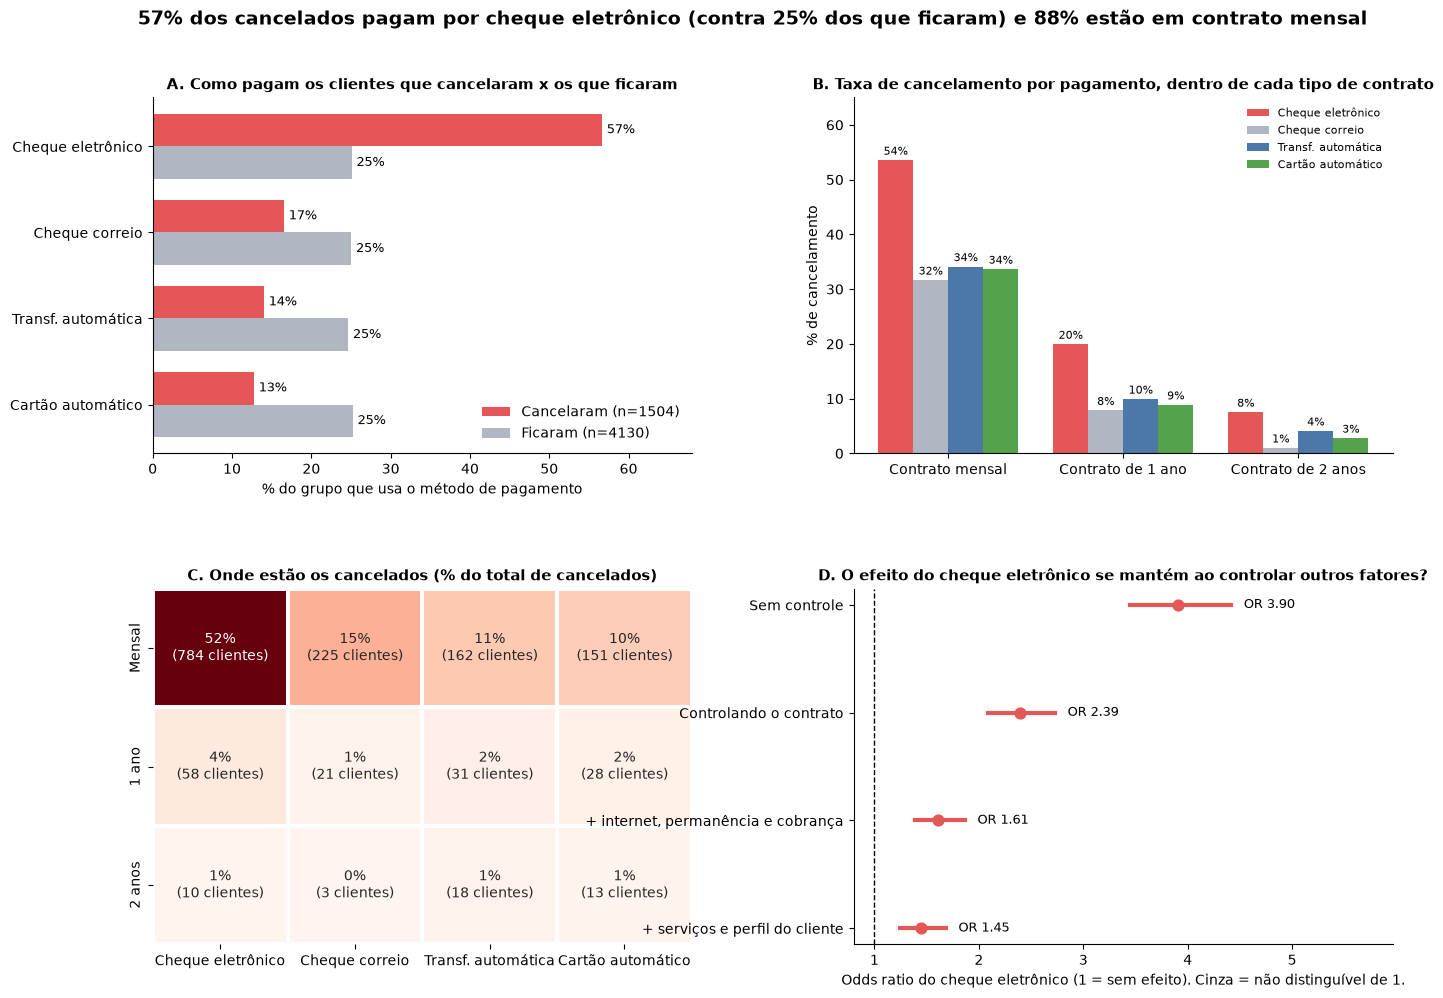

ok


In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
EM_NOTEBOOK = "ipykernel" in sys.modules
if EM_NOTEBOOK:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")
else:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import chi2_contingency
 
warnings.filterwarnings("ignore")
try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
OUT = ROOT / "graficos"
OUT.mkdir(exist_ok=True)
 
BLUE, RED, GRAY, GREEN, ORANGE = "#4C78A8", "#E45756", "#B0B7C3", "#54A24B", "#F58518"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
 
g = pd.read_csv(ROOT / "dados" / "gold" / "history_gold.csv")
g["Contrato_PT"] = g.Contrato.map({"Month-to-month": "Mensal", "One year": "1 ano", "Two year": "2 anos"})
g["Internet_PT"] = g.Servico_Internet.map({"Fiber optic": "Fibra", "DSL": "DSL", "No": "Sem internet"})
g["Pagamento_PT"] = g.Metodo_Pagamento.map({
    "Electronic check": "Cheque eletrônico", "Mailed check": "Cheque correio",
    "Bank transfer (automatic)": "Transf. automática", "Credit card (automatic)": "Cartão automático"})
ORD_C = ["Mensal", "1 ano", "2 anos"]
ORD_P = ["Cheque eletrônico", "Cheque correio", "Transf. automática", "Cartão automático"]
COR_P = {"Cheque eletrônico": RED, "Cheque correio": GRAY, "Transf. automática": BLUE, "Cartão automático": GREEN}
canc, fica = g[g.Cancelou == 1], g[g.Cancelou == 0]
g["CE"] = (g.Pagamento_PT == "Cheque eletrônico").astype(float)
 
# ---------------------------------------------------------------- números-chave
sh_c = canc.Pagamento_PT.value_counts(normalize=True).reindex(ORD_P) * 100
sh_f = fica.Pagamento_PT.value_counts(normalize=True).reindex(ORD_P) * 100
mensal_c = (canc.Contrato_PT == "Mensal").mean() * 100
mensal_f = (fica.Contrato_PT == "Mensal").mean() * 100
_, p_chi, _, _ = chi2_contingency(pd.crosstab(g.Pagamento_PT, g.Cancelou))
print(f"Cancelados: {len(canc)} | cheque eletrônico {sh_c['Cheque eletrônico']:.1f}% (ficaram: {sh_f['Cheque eletrônico']:.1f}%) | "
      f"contrato mensal {mensal_c:.1f}% (ficaram: {mensal_f:.1f}%) | qui-quadrado pagamento x cancelamento p={p_chi:.1e}")
print("Cancelados em mensal + cheque eletrônico:",
      f"{((canc.Contrato_PT == 'Mensal') & (canc.Pagamento_PT == 'Cheque eletrônico')).mean() * 100:.1f}%")
 
 
# ---------------------------------------------------------------- modelos: o efeito do cheque eletrônico se mantém?
def or_ce(extra):
    X = pd.concat([g[["CE"]]] + extra, axis=1).astype(float)
    m = sm.Logit(g.Cancelou, sm.add_constant(X)).fit(disp=0)
    ci = np.exp(m.conf_int().loc["CE"])
    return np.exp(m.params["CE"]), ci[0], ci[1], m.pvalues["CE"]
 
 
dum_c = pd.get_dummies(g.Contrato_PT).drop(columns="Mensal")
dum_i = pd.get_dummies(g.Internet_PT).drop(columns="DSL")
ctrl_perfil = pd.DataFrame({"perm12": g.Tempo_Permanencia_Meses / 12, "cob10": g.Cobranca_Mensal / 10})
ctrl_serv = g[["Seguranca_Online", "Backup_Online", "Protecao_Dispositivo", "Suporte_Tecnico",
               "Cliente_Idoso", "Parceiro", "Dependentes", "Faturamento_Sem_Papel"]]
modelos = [("Sem controle", []),
           ("Controlando o contrato", [dum_c]),
           ("+ internet, permanência e cobrança", [dum_c, dum_i, ctrl_perfil]),
           ("+ serviços e perfil do cliente", [dum_c, dum_i, ctrl_perfil, ctrl_serv])]
res = pd.DataFrame([dict(zip(["OR", "lo", "hi", "p"], or_ce(e)), modelo=n) for n, e in modelos]).set_index("modelo")
print(res.round(3).to_string())
 
# ---------------------------------------------------------------- figura
fig, axes = plt.subplots(2, 2, figsize=(16, 11), gridspec_kw={"hspace": 0.38, "wspace": 0.3})
 
# A. composição de quem cancela x quem fica
ax = axes[0, 0]
yy, h = np.arange(4), 0.38
ax.barh(yy - h / 2, sh_c.values, h, color=RED, label=f"Cancelaram (n={len(canc)})")
ax.barh(yy + h / 2, sh_f.values, h, color=GRAY, label=f"Ficaram (n={len(fica)})")
for i, (a, b) in enumerate(zip(sh_c.values, sh_f.values)):
    ax.text(a + 0.6, i - h / 2, f"{a:.0f}%", va="center", fontsize=9)
    ax.text(b + 0.6, i + h / 2, f"{b:.0f}%", va="center", fontsize=9)
ax.set_yticks(yy)
ax.set_yticklabels(ORD_P)
ax.invert_yaxis()
ax.set_xlim(0, max(sh_c.max(), sh_f.max()) * 1.2)
ax.set_xlabel("% do grupo que usa o método de pagamento")
ax.set_title("A. Como pagam os clientes que cancelaram x os que ficaram")
ax.legend(frameon=False, loc="lower right")
 
# B. taxa de cancelamento por pagamento dentro de cada contrato
ax = axes[0, 1]
w = 0.2
for j, pg in enumerate(ORD_P):
    taxas = [g[(g.Contrato_PT == c) & (g.Pagamento_PT == pg)].Cancelou.mean() * 100 for c in ORD_C]
    ns = [((g.Contrato_PT == c) & (g.Pagamento_PT == pg)).sum() for c in ORD_C]
    xs = np.arange(3) + (j - 1.5) * w
    ax.bar(xs, taxas, w, color=COR_P[pg], label=pg)
    for x_, t_, n_ in zip(xs, taxas, ns):
        ax.text(x_, t_ + 1, f"{t_:.0f}%", ha="center", fontsize=8)
ax.set_xticks(range(3))
ax.set_xticklabels([f"Contrato {c.lower()}" if c == "Mensal" else f"Contrato de {c}" for c in ORD_C])
ax.set_ylabel("% de cancelamento")
ax.set_ylim(0, 65)
ax.set_title("B. Taxa de cancelamento por pagamento, dentro de cada tipo de contrato")
ax.legend(frameon=False, fontsize=8, loc="upper right")
 
# C. onde se concentram os cancelados (contrato x pagamento)
ax = axes[1, 0]
ct = pd.crosstab(canc.Contrato_PT, canc.Pagamento_PT).loc[ORD_C, ORD_P]
pc = ct / ct.values.sum() * 100
lab = pc.round(0).astype(int).astype(str) + "%\n(" + ct.astype(str) + " clientes)"
sns.heatmap(pc, annot=lab, fmt="", cmap="Reds", cbar=False, linewidths=1.5, ax=ax, annot_kws={"size": 10})
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("C. Onde estão os cancelados (% do total de cancelados)")
 
# D. o efeito do cheque eletrônico depois de controlar
ax = axes[1, 1]
for i, (nome, r) in enumerate(res.iterrows()):
    cor = RED if r.lo > 1 else GRAY
    ax.plot([r.lo, r.hi], [i, i], color=cor, lw=3)
    ax.scatter(r.OR, i, color=cor, s=60, zorder=3)
    ax.text(r.hi + 0.12, i, f"OR {r.OR:.2f}", va="center", fontsize=9)
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_yticks(range(len(res)))
ax.set_yticklabels(res.index)
ax.invert_yaxis()
ax.set_xlim(0.8, max(res.hi) * 1.35)
ax.set_xlabel("Odds ratio do cheque eletrônico (1 = sem efeito). Cinza = não distinguível de 1.")
ax.set_title("D. O efeito do cheque eletrônico se mantém ao controlar outros fatores?")
 
fig.suptitle(f"{sh_c['Cheque eletrônico']:.0f}% dos cancelados pagam por cheque eletrônico (contra {sh_f['Cheque eletrônico']:.0f}% dos que ficaram) "
             f"e {mensal_c:.0f}% estão em contrato mensal", fontsize=14, fontweight="bold", y=0.96)
fig.savefig(OUT / "24_pagamento_x_cancelamento.png", dpi=150, bbox_inches="tight", facecolor="white")
if EM_NOTEBOOK:
    plt.show()
plt.close(fig)
print("ok")
 